# IPP Practical File 2 — Image Processing

**Note:** This notebook runs independently using generated sample images, so it does not depend on `building.png`. If your instructor requires real natural/outdoor and plant/skin images, replace the generated sample images with your own real images before submission.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import heapq
from skimage.feature import graycomatrix, graycoprops
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.cluster import KMeans

np.random.seed(42)
print("Libraries loaded successfully")
print("OpenCV:", cv2.__version__)

Libraries loaded successfully
OpenCV: 5.0.0


## Problem 1: Comparative Edge Detection — Sobel, Laplacian and Canny

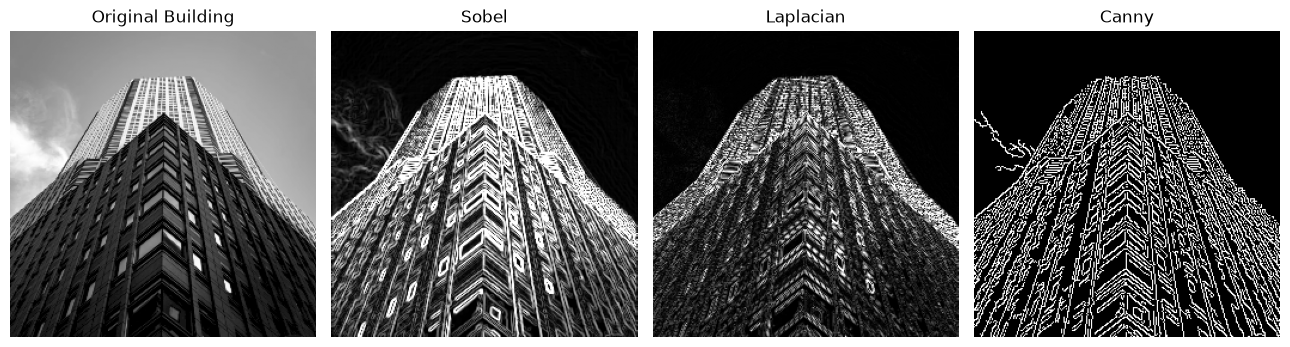

In [2]:
# Problem 1: Comparative Edge Detection

img = cv2.imread("building.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check that building.png is in the notebook folder")

img = cv2.resize(img, (256, 256))

sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(np.sqrt(sobel_x**2 + sobel_y**2))

laplacian = cv2.convertScaleAbs(
    cv2.Laplacian(img, cv2.CV_64F)
)
canny = cv2.Canny(img, 50, 150)

fig, ax = plt.subplots(1, 4, figsize=(13, 4))
for a, image, title in zip(
    ax, [img, sobel, laplacian, canny],
    ["Original Building", "Sobel", "Laplacian", "Canny"]
):
    a.imshow(image, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

**Observation:** Sobel detects intensity gradients in horizontal and vertical directions. Laplacian detects rapid intensity changes in multiple directions but can amplify noise. Canny uses smoothing and edge tracking and often produces thin, connected edges. Results depend on image content and threshold settings.

## Problem 2: Noise Sensitivity — Sobel and Laplacian

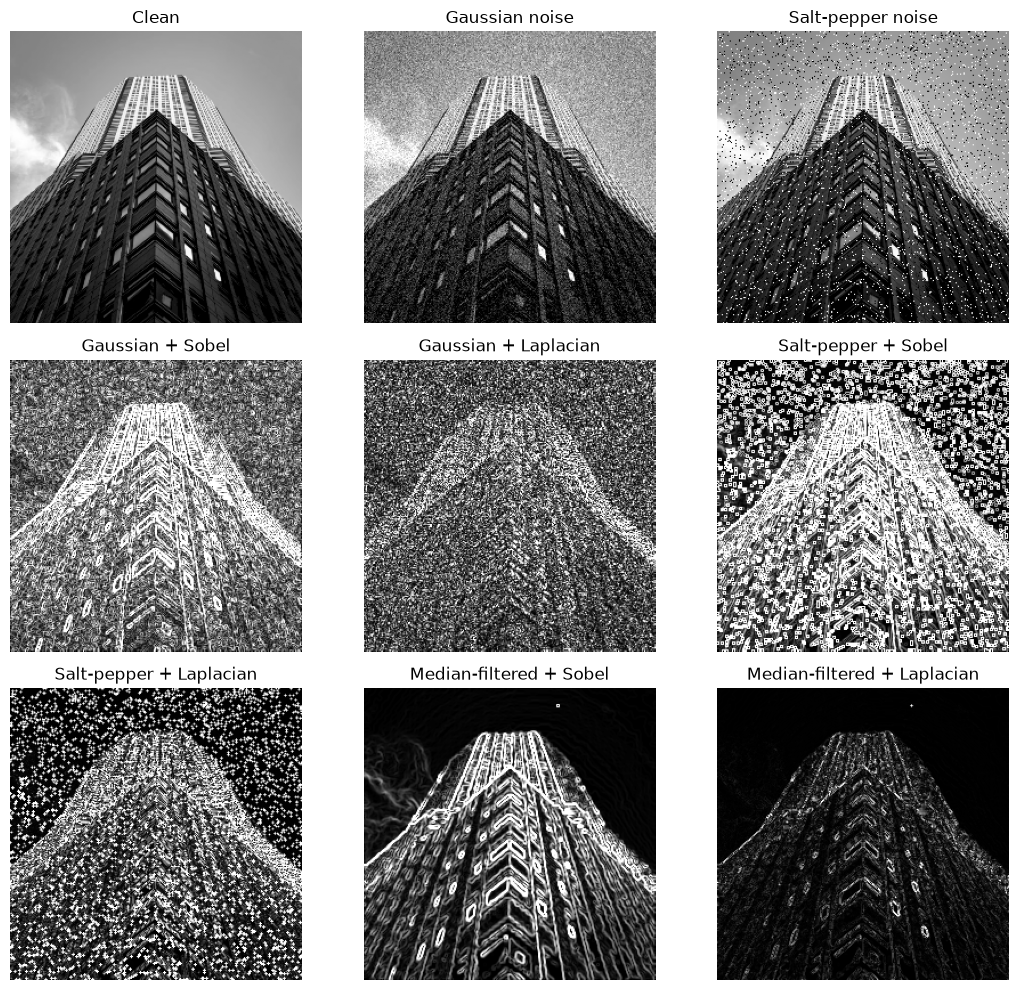

In [3]:
clean = img.copy()
gaussian_noise = np.clip(clean.astype(np.float32) + np.random.normal(0, 25, clean.shape), 0, 255).astype(np.uint8)
sp_noise = clean.copy()
rng = np.random.random(clean.shape)
sp_noise[rng < 0.04] = 0
sp_noise[rng > 0.96] = 255

def edge_pair(image):
    sx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    sob = cv2.convertScaleAbs(np.sqrt(sx**2 + sy**2))
    lap = cv2.convertScaleAbs(cv2.Laplacian(image, cv2.CV_64F))
    return sob, lap

gs, gl = edge_pair(gaussian_noise)
ss, sl = edge_pair(sp_noise)
median = cv2.medianBlur(sp_noise, 3)
ms, ml = edge_pair(median)
images = [clean, gaussian_noise, sp_noise, gs, gl, ss, sl, ms, ml]
titles = ["Clean", "Gaussian noise", "Salt-pepper noise", "Gaussian + Sobel", "Gaussian + Laplacian", "Salt-pepper + Sobel", "Salt-pepper + Laplacian", "Median-filtered + Sobel", "Median-filtered + Laplacian"]
fig, ax = plt.subplots(3, 3, figsize=(11, 10))
for a, im, title in zip(ax.flat, images, titles):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

**Observation:** Noise creates false edges and reduces clarity. Laplacian is often especially sensitive to noise. Gaussian blur can reduce Gaussian noise, while median filtering is useful for salt-and-pepper noise. Too much smoothing can remove genuine fine edges.

## Problem 3: RLE versus Huffman Compression

In [4]:
# A 20x20 image with long repeated runs
sample = np.zeros((20, 20), dtype=np.uint8)
sample[:10, :] = 50
sample[10:15, :] = 100
sample[15:, :] = 200
flat = sample.ravel()
original_bits = flat.size * 8

# RLE estimate: 8 bits for value + 8 bits for run length; split runs at 255
runs = []
value, count = int(flat[0]), 1
for item in flat[1:]:
    item = int(item)
    if item == value and count < 255:
        count += 1
    else:
        runs.append((value, count)); value, count = item, 1
runs.append((value, count))
rle_bits = len(runs) * 16

# Huffman code length calculation
freq = Counter(map(int, flat))
heap = [[f, [[symbol, ""]]] for symbol, f in freq.items()]
heapq.heapify(heap)
if len(heap) == 1:
    huffman_lengths = {heap[0][1][0][0]: 1}
else:
    while len(heap) > 1:
        left = heapq.heappop(heap); right = heapq.heappop(heap)
        for item in left[1]: item[1] = "0" + item[1]
        for item in right[1]: item[1] = "1" + item[1]
        heapq.heappush(heap, [left[0] + right[0], left[1] + right[1]])
    huffman_lengths = {symbol: len(code) for symbol, code in heap[0][1]}
huffman_bits = sum(freq[symbol] * length for symbol, length in huffman_lengths.items())

print("Original size:", original_bits, "bits")
print("RLE estimated size:", rle_bits, "bits")
print("Huffman data size (excluding tree/header):", huffman_bits, "bits")
print("RLE reduction:", round(100 * (1 - rle_bits/original_bits), 2), "%")
print("Huffman reduction:", round(100 * (1 - huffman_bits/original_bits), 2), "%")
print("RLE runs:", len(runs))

Original size: 3200 bits
RLE estimated size: 48 bits
Huffman data size (excluding tree/header): 600 bits
RLE reduction: 98.5 %
Huffman reduction: 81.25 %
RLE runs: 3


**Observation:** RLE is effective when consecutive pixels repeat, while Huffman coding gives shorter codes to frequent symbols. These are theoretical comparisons: the RLE estimate assumes 8 bits each for value and run length, and Huffman size excludes tree/header overhead. Actual file size may differ.

## Problem 4: JPEG-style 8×8 DCT, Quantization, PSNR and SSIM

Factor 0.5: PSNR=32.14 dB, SSIM=0.9541
Factor 1.0: PSNR=28.35 dB, SSIM=0.9137
Factor 2.0: PSNR=25.75 dB, SSIM=0.8586


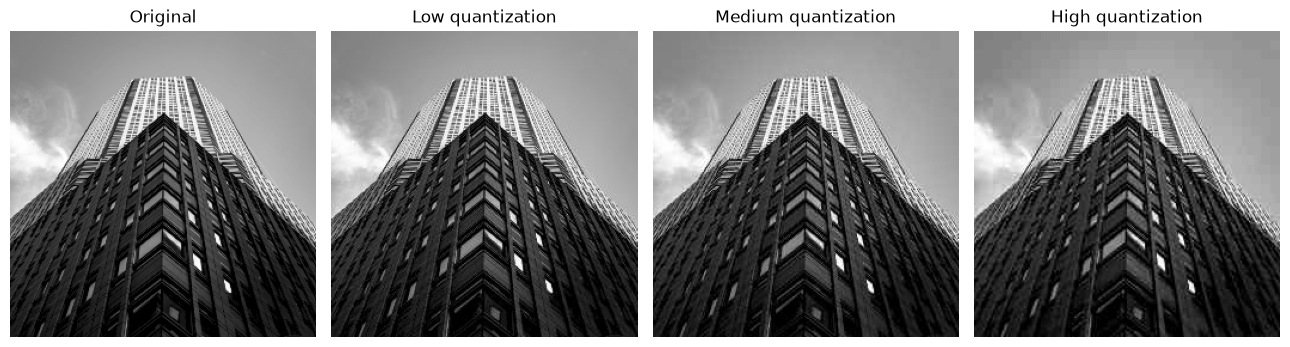

In [5]:
Q = np.array([
[16,11,10,16,24,40,51,61], [12,12,14,19,26,58,60,55],
[14,13,16,24,40,57,69,56], [14,17,22,29,51,87,80,62],
[18,22,37,56,68,109,103,77], [24,35,55,64,81,104,113,92],
[49,64,78,87,103,121,120,101], [72,92,95,98,112,100,103,99]
], dtype=np.float32)

def jpeg_dct_demo(image, factor):
    h, w = image.shape
    rec = np.zeros((h, w), dtype=np.float32)
    for y in range(0, h, 8):
        for x in range(0, w, 8):
            block = image[y:y+8, x:x+8].astype(np.float32) - 128
            coeff = cv2.dct(block)
            quantized = np.round(coeff / (Q * factor))
            restored = cv2.idct(quantized * (Q * factor)) + 128
            rec[y:y+8, x:x+8] = restored
    return np.clip(rec, 0, 255).astype(np.uint8)

jpeg_results = []
for factor in [0.5, 1.0, 2.0]:
    result = jpeg_dct_demo(img, factor)
    jpeg_results.append(result)
    print(f"Factor {factor}: PSNR={peak_signal_noise_ratio(img, result, data_range=255):.2f} dB, SSIM={structural_similarity(img, result, data_range=255):.4f}")
fig, ax = plt.subplots(1, 4, figsize=(13, 4))
for a, im, title in zip(ax, [img] + jpeg_results, ["Original", "Low quantization", "Medium quantization", "High quantization"]):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

**Observation:** Stronger quantization discards more DCT information and generally reduces PSNR and SSIM. It may create visible block boundaries, ringing, and texture loss. PSNR measures pixel-level error; SSIM measures structural similarity. The factor values here are demonstration settings, not official JPEG quality values.

## Problem 5: GLCM Texture Segmentation using K-Means

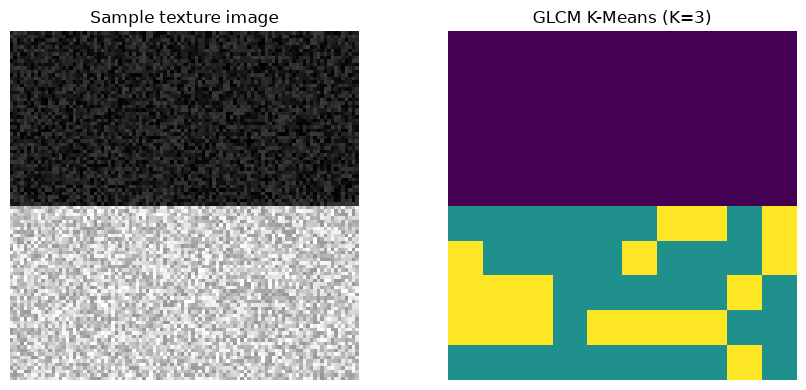

Features used: contrast, energy, homogeneity
Clusters created: 3


In [6]:
# Create an image with two different texture regions
texture_img = np.zeros((100, 100), dtype=np.uint8)
texture_img[:50, :] = np.random.randint(0, 60, (50, 100), dtype=np.uint8)
texture_img[50:, :] = np.random.randint(150, 256, (50, 100), dtype=np.uint8)
# Quantize intensity to 8 levels for GLCM
qimg = (texture_img // 32).astype(np.uint8)
features, positions = [], []
for y in range(0, 100, 10):
    for x in range(0, 100, 10):
        patch = qimg[y:y+10, x:x+10]
        g = graycomatrix(patch, distances=[1], angles=[0], levels=8, symmetric=True, normed=True)
        features.append([graycoprops(g, "contrast")[0,0], graycoprops(g, "energy")[0,0], graycoprops(g, "homogeneity")[0,0]])
        positions.append((y, x))
features = np.asarray(features)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(features)
segmented = np.zeros((100, 100), dtype=np.uint8)
for (y, x), label in zip(positions, labels):
    segmented[y:y+10, x:x+10] = label
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(texture_img, cmap="gray"); ax[0].set_title("Sample texture image"); ax[0].axis("off")
ax[1].imshow(segmented, cmap="viridis"); ax[1].set_title("GLCM K-Means (K=3)"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print("Features used: contrast, energy, homogeneity")
print("Clusters created:", len(np.unique(labels)))

**Observation:** GLCM describes relationships between neighboring gray levels. Contrast measures local variation, energy measures textural uniformity, and homogeneity measures similarity of neighboring values. K-Means groups patches with similar features. Results depend on patch size and feature selection.

## Problem 6: Multi-feature Segmentation for Disease Detection

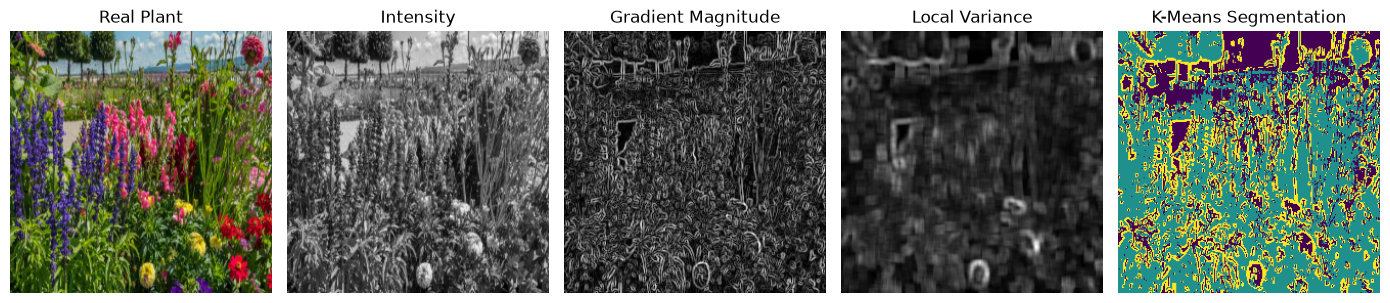

Features: intensity, gradient magnitude, local variance
Clusters: 3
Note: Segmentation does not confirm plant disease.


In [20]:
# Problem 6: Multi-feature Segmentation

plant = cv2.imread("plant.png")

if plant is None:
    raise FileNotFoundError("Check that plant.png is in the notebook folder")

plant = cv2.resize(plant, (256, 256))
gray = cv2.cvtColor(plant, cv2.COLOR_BGR2GRAY)

# Feature 1: Intensity
intensity = gray.astype(np.float32) / 255.0

# Feature 2: Gradient magnitude
gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
gradient = cv2.magnitude(gx, gy)
gradient /= gradient.max() + 1e-8

# Feature 3: Local texture variance
mean = cv2.blur(intensity, (9, 9))
sq_mean = cv2.blur(intensity**2, (9, 9))
variance = np.maximum(sq_mean - mean**2, 0)
variance /= variance.max() + 1e-8

# K-Means segmentation
features = np.column_stack([
    intensity.ravel(),
    gradient.ravel(),
    variance.ravel()
])

labels = KMeans(
    n_clusters=3, random_state=42, n_init=10
).fit_predict(features)

segmented = labels.reshape(gray.shape)

fig, ax = plt.subplots(1, 5, figsize=(14, 4))
images = [
    cv2.cvtColor(plant, cv2.COLOR_BGR2RGB),
    intensity, gradient, variance, segmented
]
titles = [
    "Real Plant", "Intensity", "Gradient Magnitude",
    "Local Variance", "K-Means Segmentation"
]

for a, image, title in zip(ax, images, titles):
    a.imshow(
        image,
        cmap="gray" if title != "K-Means Segmentation" else "viridis"
    )
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

print("Features: intensity, gradient magnitude, local variance")
print("Clusters:", len(np.unique(labels)))
print("Note: Segmentation does not confirm plant disease.")

**Observation:** Intensity represents brightness, gradient magnitude highlights boundaries, and local variance captures local texture changes. Combining features can separate regions that look similar in intensity alone. Some regions may still be misclassified. Evaluation requires real plant/skin images and labelled ground truth; this generated example does not diagnose disease.

## Overall Conclusion

This practical demonstrated edge detection, noise sensitivity, RLE and Huffman coding, JPEG-style DCT quantization, GLCM texture segmentation, and multi-feature image segmentation. The best method depends on image characteristics and the intended application. Compression introduces a trade-off between file size and quality, while noise and feature selection affect segmentation results. Real images and reference labels are needed to validate performance for real-world applications.